
## Assignment Objective

In this assignment, you will build a **Variational Autoencoder (VAE)** using Keras.  
The VAE will learn a compressed probabilistic latent representation of MNIST images and generate new handwritten digit-like images by sampling from the latent space.


## Task 1: Import Required Libraries

In this section, we import TensorFlow, Keras layers, NumPy, and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Task 2: Load and Preprocess the MNIST Dataset

MNIST contains grayscale images of handwritten digits from 0 to 9.

Each image has size:

```text
28 x 28 pixels
```

For the VAE, we normalize pixel values to the range `[0, 1]` and flatten each image into a vector of size `784`.

In [2]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images from 28x28 to 784-dimensional vectors
original_dim = 28 * 28
x_train_flat = x_train.reshape((x_train.shape[0], original_dim))
x_test_flat = x_test.reshape((x_test.shape[0], original_dim))

print("Training data shape:", x_train_flat.shape)
print("Testing data shape:", x_test_flat.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 784)
Testing data shape: (10000, 784)


## Task 3: Visualize Sample MNIST Images

Before building the model, let us look at a few sample images from the dataset.

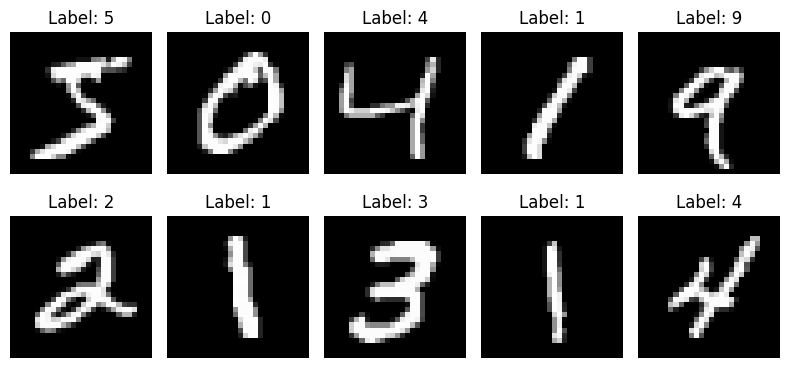

In [3]:
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Task 4: Set Hyperparameters

For this assignment, we use a **2-dimensional latent space** so that we can visualize the learned representation.

You may experiment later with larger latent dimensions such as 8, 16, or 32.

In [4]:
input_dim = 784
hidden_dim = 256
latent_dim = 2

batch_size = 128
epochs = 20
learning_rate = 0.001

## Task 5: Define the Sampling Layer

A Variational Autoencoder does not directly learn one fixed latent vector.

Instead, the encoder learns:

- `z_mean`: the mean of the latent distribution
- `z_log_var`: the log variance of the latent distribution

The sampling layer applies the **reparameterization trick**:

```text
z = mean + standard deviation × random noise
```

This allows the model to sample from the latent distribution while still supporting backpropagation.

In [5]:
class Sampling(layers.Layer):
    """Uses z_mean and z_log_var to sample latent vector z."""

    def call(self, inputs):
        z_mean, z_log_var = inputs

        # Get batch size and latent dimension dynamically
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]

        # Sample random noise from a standard normal distribution
        epsilon = tf.random.normal(shape=(batch, dim))

        # Reparameterization trick
        z = z_mean + tf.exp(0.5 * z_log_var) * epsilon

        return z

## Task 6: Build the Encoder

The encoder maps each input image into a latent probability distribution.

Architecture:

```text
Input image vector → Dense layer → z_mean and z_log_var → Sampling layer → z
```

In [6]:
# Encoder input
encoder_inputs = keras.Input(shape=(input_dim,), name="encoder_input")

# Hidden layer
x = layers.Dense(hidden_dim, activation="relu")(encoder_inputs)

# Mean and log variance of latent distribution
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

# Sampling layer
z = Sampling()([z_mean, z_log_var])

# Encoder model
encoder = keras.Model(
    encoder_inputs,
    [z_mean, z_log_var, z],
    name="encoder"
)

encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    200,960 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        514 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        514 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 201,988 (789.02 KB)

 Trainable params: 201,988 (789.02 KB)

 Non-trainable params: 0 (0.00 B)

## Task 7: Build the Decoder

The decoder maps a sampled latent vector back into an image.

Architecture:

```text
Latent vector z → Dense layer → Reconstructed image vector
```

The output layer uses `sigmoid` activation because MNIST pixel values are normalized between 0 and 1.

In [7]:
# Decoder input
latent_inputs = keras.Input(shape=(latent_dim,), name="z_sampling")

# Hidden layer
x = layers.Dense(hidden_dim, activation="relu")(latent_inputs)

# Output reconstructed image
decoder_outputs = layers.Dense(input_dim, activation="sigmoid")(x)

# Decoder model
decoder = keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)

decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ z_sampling (InputLayer)         │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 202,256 (790.06 KB)

 Trainable params: 202,256 (790.06 KB)

 Non-trainable params: 0 (0.00 B)

## Task 8: Define the VAE Model

A VAE requires a custom training step because the loss has two components:

1. **Reconstruction loss**  
   Measures how close the reconstructed image is to the original image.

2. **KL divergence loss**  
   Regularizes the latent distribution so that it stays close to a standard normal distribution.

The total loss is:

```text
Total Loss = Reconstruction Loss + KL Divergence Loss
```

In [8]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

        # Track losses during training
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        # Keras may pass data as tuple; extract the input
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)

            # Reconstruction loss
            # Binary cross-entropy is computed per feature, then summed across pixels.
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=-1
                )
            )

            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        # Compute gradients and update weights
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # Update trackers
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstruction = self.decoder(z)
        return reconstruction

## Task 9: Compile and Train the VAE

Now we compile the model using the Adam optimizer and train it on MNIST.

Because this is an unsupervised generative model, we only use the images, not the class labels.

In [9]:
vae = VAE(encoder, decoder)

vae.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
    loss=keras.losses.BinaryCrossentropy()
)

history = vae.fit(
    x_train_flat,
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True
)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - kl_loss: 2.4963 - loss: 36.7988 - reconstruction_loss: 34.3025
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - kl_loss: 2.0389 - loss: 30.7359 - reconstruction_loss: 28.6970
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - kl_loss: 2.2477 - loss: 30.2803 - reconstruction_loss: 28.0327
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - kl_loss: 2.3555 - loss: 30.0956 - reconstruction_loss: 27.7401
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - kl_loss: 2.4202 - loss: 29.9655 - reconstruction_loss: 27.5453
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - kl_loss: 2.4699 - loss: 29.8339 - reconstruction_loss: 27.3640
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - kl_loss: 2.5302 - loss: 29.7284 - reconstruction_loss: 27.1983
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - kl_loss: 2.5955 - loss: 29.6420 - reconstruction_loss: 27.0465
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - 

## Task 10: Plot Training Loss

The total loss should generally decrease during training.

The loss includes both reconstruction loss and KL divergence loss.

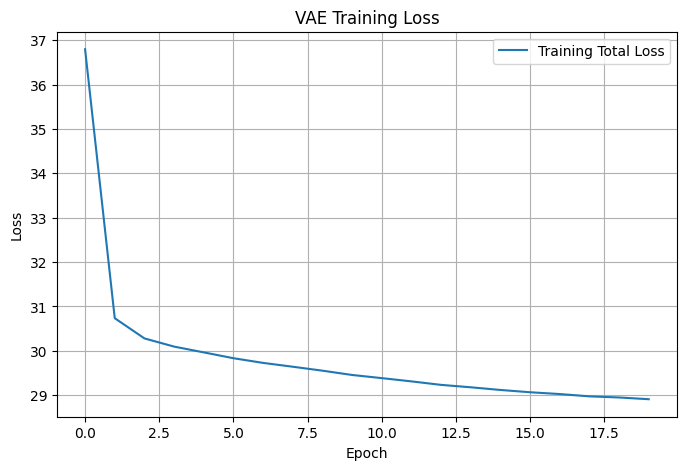

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Total Loss")

if "val_loss" in history.history:
    plt.plot(history.history["val_loss"], label="Validation Total Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True)
plt.show()

## Task 11: Reconstruct MNIST Images

In this section, we pass test images through the VAE and compare the original images with the reconstructed images.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


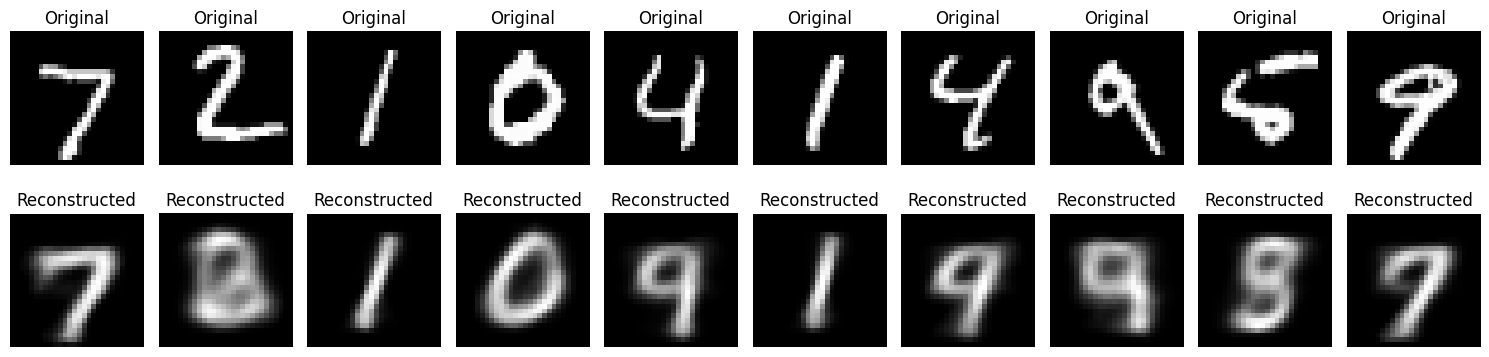

In [11]:
def plot_reconstructions(model, x_data, n=10):
    # Select first n images
    test_images = x_data[:n]

    # Reconstruct images
    reconstructed = model.predict(test_images)

    plt.figure(figsize=(15, 4))

    for i in range(n):
        # Original image
        plt.subplot(2, n, i + 1)
        plt.imshow(test_images[i].reshape(28, 28), cmap="gray")
        plt.title("Original")
        plt.axis("off")

        # Reconstructed image
        plt.subplot(2, n, i + 1 + n)
        plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_reconstructions(vae, x_test_flat, n=10)

## Task 12: Generate New Digits from Random Latent Vectors

The main goal of a generative model is to create new samples.

Here, we sample random points from the latent space and pass them through the decoder.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


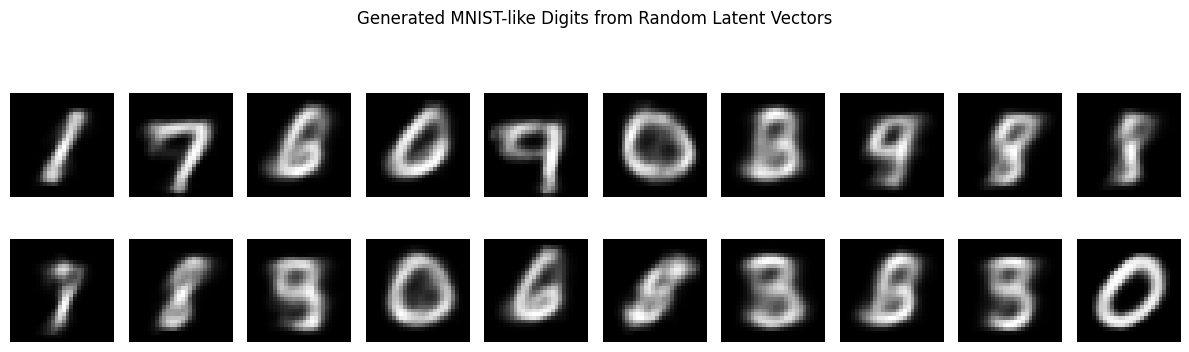

In [12]:
def generate_random_digits(decoder, latent_dim=2, n=20):
    # Sample random latent vectors from standard normal distribution
    random_latent_vectors = np.random.normal(size=(n, latent_dim))

    # Decode latent vectors into images
    generated_images = decoder.predict(random_latent_vectors)

    plt.figure(figsize=(12, 4))

    for i in range(n):
        plt.subplot(2, n // 2, i + 1)
        plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
        plt.axis("off")

    plt.suptitle("Generated MNIST-like Digits from Random Latent Vectors")
    plt.tight_layout()
    plt.show()

generate_random_digits(decoder, latent_dim=latent_dim, n=20)




## Task 13: Visualize the 2D Latent Space

Because we used a 2-dimensional latent space, we can plot the encoded test images.

Each point represents an image in the learned latent space.  
The color represents the true digit label.

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


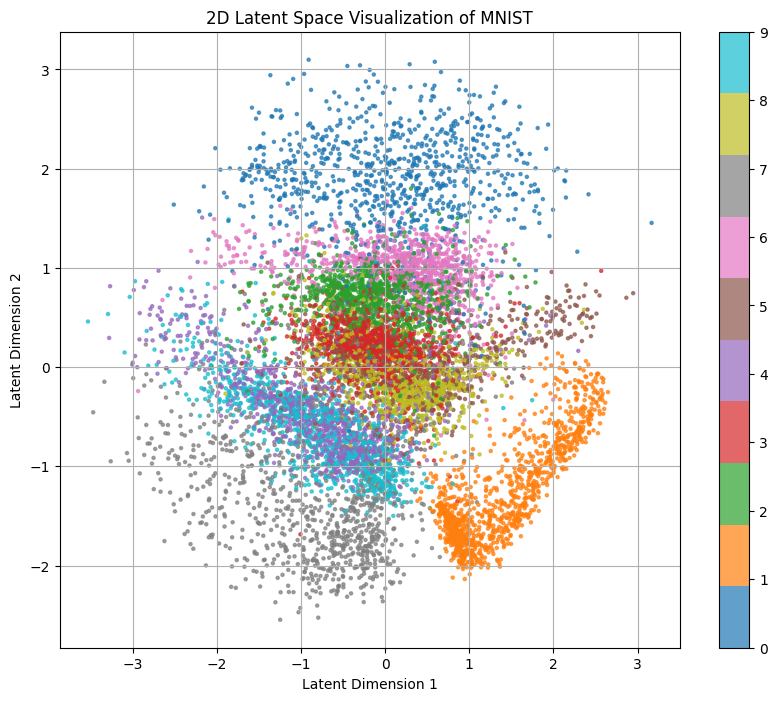

In [13]:
# Encode test images
z_mean_test, z_log_var_test, z_test = encoder.predict(x_test_flat, batch_size=128)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    z_mean_test[:, 0],
    z_mean_test[:, 1],
    c=y_test,
    cmap="tab10",
    s=5,
    alpha=0.7
)

plt.colorbar(scatter, ticks=range(10))
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("2D Latent Space Visualization of MNIST")
plt.grid(True)
plt.show()